<a href="https://colab.research.google.com/github/OrastaRakhmatullayeva/ML-projects/blob/main/Perceptron_HOMEWORK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HOMEWORK: Perceptron


## 1-topshiriq. Nazariy savollar

**1. Perceptronning to'rt qismi.**
- **Kirishlar ($x_i$)**: modelga beriladigan xususiyatlar (feature).
- **Vaznlar ($w_i$)**: har bir kirish qarorga qanchalik ta'sir qilishini bildiradi; o'rganish jarayonida aynan shular o'zgaradi.
- **Bias ($b$)**: ajratuvchi chiziqni siljitadi, ya'ni neyron qanchalik oson "yonishini" belgilaydi.
- **Funksiya (step)**: yig'indi $z$ ni 0 yoki 1 ga aylantiradi

**2. Bias nima uchun kerak?** Bias chegarani koordinata boshidan siljitish imkonini beradi. Agar $b=0$ bo'lsa, ajratuvchi chiziq $w_1x_1+w_2x_2=0$ doim koordinata boshi $(0,0)$ dan o'tishga majbur bo'ladi va ko'p masalalarni yecha olmaydi.

**3.** $w_1=1,\ w_2=1,\ b=-1.5$:

| $x_1$ | $x_2$ | $z$ | $\hat y$ |
|---|---|---|---|
| 0 | 0 | −1.5 | 0 |
| 0 | 1 | −0.5 | 0 |
| 1 | 0 | −0.5 | 0 |
| 1 | 1 | 0.5 | 1 |

Bu **AND** funksiyasi.

**4.** Bashorat to'g'ri bo'lsa $y=\hat y$, demak $y-\hat y=0$. Formuladan: $w_i \leftarrow w_i + \eta\cdot 0\cdot x_i = w_i$ va $b \leftarrow b+\eta\cdot 0 = b$. Shuning uchun hech narsa o'zgarmaydi.

**5.** XOR da $(0,0)$ va $(1,1)$ sinf 0, $(0,1)$ va $(1,0)$ sinf 1. Tekislikda bu nuqtalar kvadratning diagonallarida joylashadi: bir sinf bir diagonalda, ikkinchisi ikkinchi diagonalda. Bitta to'g'ri chiziq bilan har ikki diagonalni bir-biridan ajratib bo'lmaydi, shuning uchun bitta perceptron XOR ni yecha olmaydi.

## 2-topshiriq. Qo'lda hisoblash (AND)

Boshlang'ich holat: $w_1=w_2=0,\ b=0,\ \eta=1$. Eslatma: $z=0$ bo'lsa $\hat y=1$.

| Epoch | x1 | x2 | y | z | ŷ | y−ŷ | yangi w1 | yangi w2 | yangi b |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 0 | 0 | 0 | 0 | 1 | −1 | 0 | 0 | −1 |
| 1 | 0 | 1 | 0 | −1 | 0 | 0 | 0 | 0 | −1 |
| 1 | 1 | 0 | 0 | −1 | 0 | 0 | 0 | 0 | −1 |
| 1 | 1 | 1 | 1 | −1 | 0 | +1 | 1 | 1 | 0 |
| 2 | 0 | 0 | 0 | 0 | 1 | −1 | 1 | 1 | −1 |
| 2 | 0 | 1 | 0 | 0 | 1 | −1 | 1 | 0 | −2 |
| 2 | 1 | 0 | 0 | −1 | 0 | 0 | 1 | 0 | −2 |
| 2 | 1 | 1 | 1 | −1 | 0 | +1 | 2 | 1 | −1 |

**Savollar:**
- **2-epoch oxirida barcha 4 namuna to'g'rimi?** Yo'q. Oxirgi vaznlar $w=(2,1),\ b=-1$ bilan tekshiramiz: $(0,0)$: $z=-1\to0$ ✓; $(0,1)$: $z=0\to1$ ✗ (kerak 0); $(1,0)$: $z=1\to1$ ✗ (kerak 0); $(1,1)$: $z=2\to1$ ✓. Ikkita xato bor, demak o'rganish davom etishi kerak.
- **Eng ko'p o'zgargan namuna:** $(1,1)$ (ikkala epochda ham). Chunki yangilanish $\Delta w_i=\eta(y-\hat y)x_i$ va bu namunada ikkala $x_i=1$, shuning uchun $w_1$, $w_2$ va $b$ uchalasi ham bir vaqtda o'zgaradi. $(0,0)$ da faqat bias o'zgaradi.
- **Kod bilan solishtirish:** quyidagi katakdagi kod aynan shu jadvalni chiqaradi va natijalar mos keladi. Kod bo'yicha to'liq o'rganish 6-epochda yakunlanadi ($w=(2,1),\ b=-3$).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_and = np.array([0, 0, 0, 1])

w = np.zeros(2)
b = 0.0
print("epoch x1 x2 y   z  yhat  y-yhat  w1  w2   b")
for epoch in (1, 2):
    for xi, yi in zip(X, y_and):
        z = w @ xi + b
        yhat = int(z >= 0)
        err = yi - yhat
        w = w + 1 * err * xi
        b = b + 1 * err
        print(f"{epoch:5d} {xi[0]:2d} {xi[1]:2d} {yi:1d} {z:4.0f} {yhat:5d} {err:7d} {w[0]:3.0f} {w[1]:3.0f} {b:3.0f}")

epoch x1 x2 y   z  yhat  y-yhat  w1  w2   b
    1  0  0 0    0     1      -1   0   0  -1
    1  0  1 0   -1     0       0   0   0  -1
    1  1  0 0   -1     0       0   0   0  -1
    1  1  1 1   -1     0       1   1   1   0
    2  0  0 0    0     1      -1   1   1  -1
    2  0  1 0    0     1      -1   1   0  -2
    2  1  0 0   -1     0       0   1   0  -2
    2  1  1 1   -1     0       1   2   1  -1


## 3-topshiriq. Perceptronni noldan yozish

Faqat `numpy` ishlatilgan. 4-topshiriqdagi tajriba uchun sinfga ixtiyoriy `random_init` va `seed` parametrlari qo'shilgan; ular berilmasa vaznlar nol bilan boshlanadi. `predict` ichidagi `np.round(z, 10)` suzuvchi nuqta xatoligidan (masalan $0.1+0.1-0.2$ aniq 0 chiqmasligi) saqlaydi.

In [ ]:
class Perceptron:
    def __init__(self, lr=0.1, epochs=20, random_init=False, seed=None):
        self.lr = lr
        self.epochs = epochs
        self.random_init = random_init
        self.seed = seed
        self.w = None
        self.b = 0.0
        self.errors_per_epoch = []

    def predict(self, X):
        z = X @ self.w + self.b
        return np.where(np.round(z, 10) >= 0, 1, 0)

    def fit(self, X, y):
        if self.random_init:
            rng = np.random.default_rng(self.seed)
            self.w = rng.standard_normal(X.shape[1])
            self.b = float(rng.standard_normal())
        else:
            self.w = np.zeros(X.shape[1])
            self.b = 0.0
        self.errors_per_epoch = []
        for epoch in range(self.epochs):
            errors = 0
            for xi, yi in zip(X, y):
                y_pred = self.predict(xi)
                error = yi - y_pred
                self.w = self.w + self.lr * error * xi
                self.b = self.b + self.lr * error
                if error != 0:
                    errors += 1
            self.errors_per_epoch.append(errors)
        return self

def first_zero_epoch(errors):
    for i, e in enumerate(errors):
        if e == 0:
            return i + 1
    return None

y_or = np.array([0, 1, 1, 1])
y_nand = np.array([1, 1, 1, 0])

for name, y in [("AND", y_and), ("OR", y_or), ("NAND", y_nand)]:
    p = Perceptron(lr=0.1, epochs=20).fit(X, y)
    print(name)
    print("  w =", p.w, " b =", round(p.b, 4))
    print("  errors_per_epoch =", p.errors_per_epoch)
    print("  predict =", p.predict(X), " kerak =", y)
    print("  xatosiz birinchi epoch =", first_zero_epoch(p.errors_per_epoch))

AND
  w = [0.2 0.1]  b = -0.3
  errors_per_epoch = [2, 3, 3, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
  predict = [0 0 0 1]  kerak = [0 0 0 1]
  xatosiz birinchi epoch = 6
OR
  w = [0.1 0.1]  b = -0.1
  errors_per_epoch = [2, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
  predict = [0 1 1 1]  kerak = [0 1 1 1]
  xatosiz birinchi epoch = 4
NAND
  w = [-0.2 -0.1]  b = 0.2
  errors_per_epoch = [1, 3, 3, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
  predict = [1 1 1 0]  kerak = [1 1 1 0]
  xatosiz birinchi epoch = 6


**To'liq o'rganish uchun kerak bo'lgan epoch ($\eta=0.1$, nol boshlang'ich vaznlar):**

| Funksiya | Xatosiz birinchi epoch | Oxirgi xatoli epoch |
|---|---|---|
| AND | 6 | 5 |
| OR | 4 | 3 |
| NAND | 6 | 5 |

("Xatosiz birinchi epoch" — shu epochda 4 namunaning hammasi to'g'ri chiqqan va yangilanish bo'lmagan; vaznlar undan oldingi epochda topilgan.)

## 4-topshiriq. Tajribalar va xulosa

### 4.1. XOR tajribasi

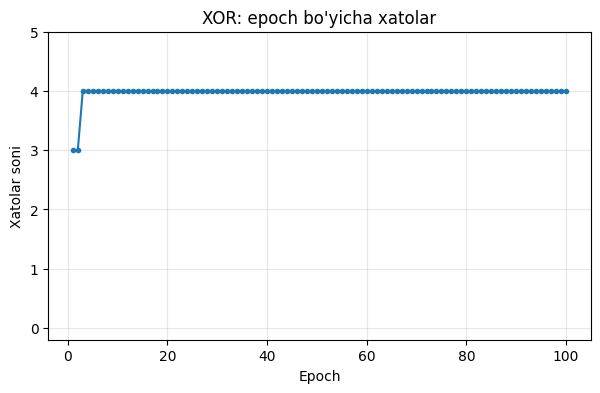

eng kam xato: 3
oxirgi 5 epoch: [4, 4, 4, 4, 4]


In [ ]:
y_xor = np.array([0, 1, 1, 0])
p = Perceptron(lr=0.1, epochs=100).fit(X, y_xor)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 101), p.errors_per_epoch, marker="o", markersize=3)
plt.xlabel("Epoch")
plt.ylabel("Xatolar soni")
plt.title("XOR: epoch bo'yicha xatolar")
plt.ylim(-0.2, 5)
plt.grid(alpha=0.3)
plt.show()

print("eng kam xato:", min(p.errors_per_epoch))
print("oxirgi 5 epoch:", p.errors_per_epoch[-5:])

**Xulosa:** Xato nolga tushmaydi, u 100 epoch davomida 3–4 atrofida qolib ketadi. Sabab: XOR chiziqli ajralmaydi, ya'ni 4 nuqtani to'g'ri ajratadigan bitta to'g'ri chiziq mavjud emas. Konvergensiya teoremasi faqat chiziqli ajraladigan ma'lumotlar uchun kafolat beradi, shuning uchun vaznlar to'xtamasdan siljib yuraveradi.

### 4.2. Learning rate tajribasi (AND)

In [ ]:
for lr in [0.01, 0.1, 1]:
    p = Perceptron(lr=lr, epochs=50).fit(X, y_and)
    print(f"lr={lr:<5} w={p.w}  b={p.b:.3f}  xatosiz birinchi epoch={first_zero_epoch(p.errors_per_epoch)}  errors={p.errors_per_epoch[:8]}")

lr=0.01  w=[0.02 0.01]  b=-0.030  xatosiz birinchi epoch=6  errors=[2, 3, 3, 2, 1, 0, 0, 0]
lr=0.1   w=[0.2 0.1]  b=-0.300  xatosiz birinchi epoch=6  errors=[2, 3, 3, 2, 1, 0, 0, 0]
lr=1     w=[2. 1.]  b=-3.000  xatosiz birinchi epoch=6  errors=[2, 3, 3, 2, 1, 0, 0, 0]


**Xulosa:** Epoch soni o'zgarmadi: uchala $\eta$ da ham 6-epochda xatosiz holatga kelinadi va xatolar ketma-ketligi bir xil (`[2, 3, 3, 2, 1, 0]`). Sabab: vaznlarni nol bilan boshlayapmiz, shuning uchun $\eta$ barcha yangilanishlarni bir xil songa ko'paytiradi, ya'ni $w$ va $b$ faqat masshtab bo'yicha o'zgaradi ($\eta=1$ dagi vektor $\eta=0.1$ dagisidan 10 baravar katta). $z=w^Tx+b$ ishorasi esa masshtabga bog'liq emas, demak har bir namunadagi bashorat va xato bir xil bo'ladi. $\eta$ faqat vaznlarning kattaligini o'zgartiradi, chegara chizig'ini emas.

### 4.3. Tasodifiy boshlang'ich vaznlar

In [ ]:
for name, y in [("AND", y_and), ("OR", y_or)]:
    for lr in [0.01, 0.1, 1]:
        res = []
        for seed in range(10):
            p = Perceptron(lr=lr, epochs=500, random_init=True, seed=seed).fit(X, y)
            res.append(first_zero_epoch(p.errors_per_epoch))
        print(f"{name} lr={lr:<5} xatosiz birinchi epoch (10 marta): {res}")

AND lr=0.01  xatosiz birinchi epoch (10 marta): [41, 44, 55, 359, 139, 136, 1, 5, 180, 84]


AND lr=0.1   xatosiz birinchi epoch (10 marta): [10, 5, 8, 37, 19, 19, 1, 4, 26, 11]


AND lr=1     xatosiz birinchi epoch (10 marta): [6, 6, 6, 8, 10, 7, 1, 6, 8, 7]


OR lr=0.01  xatosiz birinchi epoch (10 marta): [81, 35, 42, 299, 235, 147, 64, 15, 142, 77]


OR lr=0.1   xatosiz birinchi epoch (10 marta): [10, 5, 7, 33, 26, 18, 8, 3, 17, 9]


OR lr=1     xatosiz birinchi epoch (10 marta): [4, 3, 4, 6, 4, 6, 2, 3, 5, 4]


**Xulosa:** Epoch soni har safar har xil chiqadi, chunki har gal boshlang'ich chiziq tasodifiy joydan va tasodifiy yo'nalishdan boshlanadi: ba'zan u allaqachon yechimga yaqin, ba'zan uzoq bo'ladi, shuning uchun to'g'rilash uchun kerak yangilanishlar soni har xil. 2-tajribadagi holat endi o'zgardi: nol boshlang'ich vaznda $\eta$ faqat masshtab edi, tasodifiy boshlang'ich vaznda esa $\eta$ boshlang'ich vaznga nisbatan qadam kattaligini belgilaydi. Kichik $\eta$ da boshlang'ich tasodifiy vaznlarni "yengish" uchun ko'p qadam kerak bo'ladi, katta $\eta$ da esa boshlang'ich vaznlar ahamiyatini yo'qotadi va natija nol bilan boshlashga yaqinlashadi. Natijada $\eta$ endi epoch soniga haqiqiy ta'sir qiladi.

## 5-topshiriq. Challenge: XOR ni 3 ta perceptron bilan yechish

$\text{XOR}(x_1,x_2)=\text{AND}(\text{OR}(x_1,x_2),\ \text{NAND}(x_1,x_2))$

| Perceptron | $w_1$ | $w_2$ | $b$ | Nima uchun ishlaydi |
|---|---|---|---|---|
| OR | 1 | 1 | −0.5 | Kamida bitta kirish 1 bo'lsa $z\ge0.5>0$, ikkalasi 0 bo'lsa $z=-0.5<0$. |
| NAND | −1 | −1 | 1.5 | Ikkalasi 1 bo'lsa $z=-0.5<0$, aks holda $z\ge0.5>0$. |
| AND | 1 | 1 | −1.5 | Faqat ikkala kirish 1 bo'lsa $z=0.5\ge0$, aks holda $z<0$. |

In [ ]:
def perceptron_unit(x1, x2, w1, w2, b):
    return 1 if w1 * x1 + w2 * x2 + b >= 0 else 0

def xor_net(x1, x2):
    h_or = perceptron_unit(x1, x2, 1, 1, -0.5)
    h_nand = perceptron_unit(x1, x2, -1, -1, 1.5)
    return perceptron_unit(h_or, h_nand, 1, 1, -1.5)

print("x1 x2 | OR NAND | XOR")
for x1, x2 in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    h_or = perceptron_unit(x1, x2, 1, 1, -0.5)
    h_nand = perceptron_unit(x1, x2, -1, -1, 1.5)
    print(f" {x1}  {x2} |  {h_or}    {h_nand}  |  {xor_net(x1, x2)}")

assert [xor_net(a, b) for a, b in [(0, 0), (0, 1), (1, 0), (1, 1)]] == [0, 1, 1, 0]

x1 x2 | OR NAND | XOR
 0  0 |  0    1  |  0
 0  1 |  1    1  |  1
 1  0 |  1    1  |  1
 1  1 |  1    0  |  0


**Oraliq chiqishlar jadvali:**

| $x_1$ | $x_2$ | OR | NAND | XOR (AND) |
|---|---|---|---|---|
| 0 | 0 | 0 | 1 | 0 |
| 0 | 1 | 1 | 1 | 1 |
| 1 | 0 | 1 | 1 | 1 |
| 1 | 1 | 1 | 0 | 0 |

**Nima uchun 2-qatlamda chiziqli ajraladigan bo'lib qoldi?** Birinchi qatlam nuqtalarni yangi fazoga (OR, NAND) ko'chiradi: $(0,0)\to(0,1)$, $(0,1)\to(1,1)$, $(1,0)\to(1,1)$, $(1,1)\to(1,0)$. Sinf 1 ikkala namuna endi bitta nuqta $(1,1)$ ga tushdi, sinf 0 nuqtalari $(0,1)$ va $(1,0)$ esa uning ikki chetida turibdi, shuning uchun ularni $h_1+h_2=1.5$ chizig'i (AND) bilan ajratish mumkin. Ya'ni yashirin qatlam ma'lumotni chiziqli ajraladigan ko'rinishga keltirdi — MLP ning asosiy g'oyasi shu.

## 6-topshiriq. Bonus: Iris

setosa vs versicolor: test accuracy = 1.00, eng kam train xato = 0


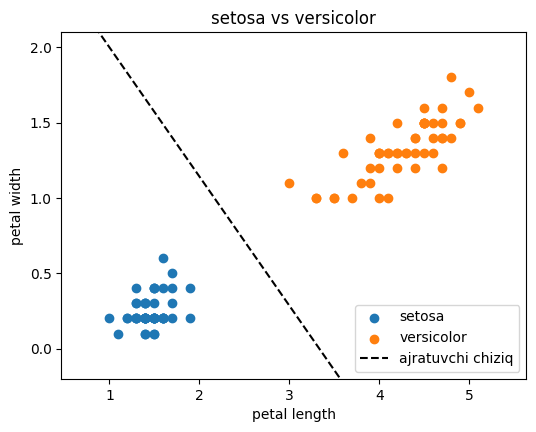

versicolor vs virginica: test accuracy = 0.85, eng kam train xato = 4


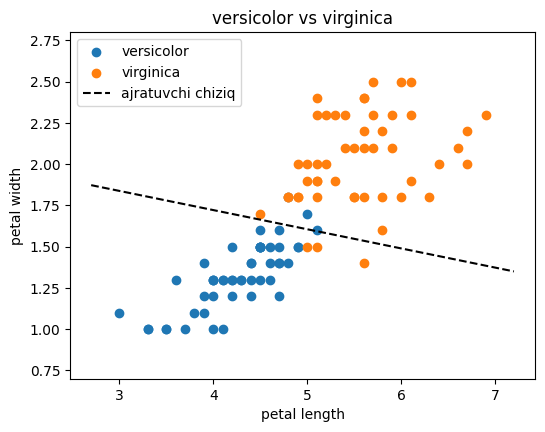

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris()

def run_pair(class_a, class_b, title):
    mask = np.isin(iris.target, [class_a, class_b])
    Xi = iris.data[mask][:, 2:4]
    yi = (iris.target[mask] == class_b).astype(int)
    X_tr, X_te, y_tr, y_te = train_test_split(Xi, yi, test_size=0.2, random_state=42, stratify=yi)
    p = Perceptron(lr=0.1, epochs=100).fit(X_tr, y_tr)
    acc = (p.predict(X_te) == y_te).mean()
    print(f"{title}: test accuracy = {acc:.2f}, eng kam train xato = {min(p.errors_per_epoch)}")

    plt.figure(figsize=(6, 4.5))
    plt.scatter(Xi[yi == 0][:, 0], Xi[yi == 0][:, 1], label=iris.target_names[class_a])
    plt.scatter(Xi[yi == 1][:, 0], Xi[yi == 1][:, 1], label=iris.target_names[class_b])
    xs = np.linspace(Xi[:, 0].min() - 0.3, Xi[:, 0].max() + 0.3, 100)
    if abs(p.w[1]) > 1e-12:
        plt.plot(xs, -(p.w[0] * xs + p.b) / p.w[1], "k--", label="ajratuvchi chiziq")
    plt.ylim(Xi[:, 1].min() - 0.3, Xi[:, 1].max() + 0.3)
    plt.xlabel("petal length")
    plt.ylabel("petal width")
    plt.title(title)
    plt.legend()
    plt.show()

run_pair(0, 1, "setosa vs versicolor")
run_pair(1, 2, "versicolor vs virginica")

**Xulosa:** setosa va versicolor petal length/width fazosida bir-biridan aniq uzoqda joylashgan, ya'ni chiziqli ajraladi, shuning uchun perceptron test aniqligi 1.00 ga yetdi va xatolar nolga tushdi. Versicolor va virginica esa chegarada bir-biriga aralashib ketadi (chiziqli ajralmaydi), shuning uchun perceptron xatosi nolga tushmaydi, test aniqligi pastroq (taxminan 0.85) va chiziq barqaror emas. Taxmin tasdiqlandi.